# Phase 6: Advanced Paradigms (2026+)
## Notebook 01: Multimodal AI — Unified Vision, Audio & Interleaved Language Pipelines

### Overview
Modern frontier AI systems (e.g., GPT-4o, Gemini, Qwen-VL, LLaVA) no longer treat images, audio, and text as isolated pipelines stitched together with brittle OCR or ASR transcripts. Instead, **Native Multimodal Architectures** project visual patches, audio spectrogram frames, and text tokens into a **single shared Transformer embedding space** $\mathbb{R}^d$.

This unlocks three breakthrough capabilities:
1. **Cross-Modal Contrastive Alignment (CLIP)**: Mapping images and text captions into a shared hypersphere where semantically matching pairs align via cosine similarity.
2. **Interleaved Multimodal Token Streams**: Mixing `[TEXT] + [IMG_PATCHES] + [AUDIO_FRAMES] + [TEXT]` in a single context window so self-attention reasons jointly across modalities.
3. **Real-Time Streaming Audio/Video Ingestion**: Processing continuous waveform STFT Log-Mel spectrograms and video keyframe buffers under strict presentation-timestamp (PTS) synchronization.

### System Architecture: Unified Interleaved Multimodal Transformer
```
   [Image (PIL RGB)]          [Audio Waveform]              [Text Prompt]
           |                         |                            |
           v                         v                            v
  +-----------------+       +------------------+        +-------------------+
  | ViT Patchifier  |       | STFT + Mel Bank  |        | Token Embeddings  |
  | (P x P patches) |       | (Log-Mel Frames) |        | (Vocab -> R^d)    |
  +-----------------+       +------------------+        +-------------------+
           |                         |                            |
           v                         v                            |
  +-----------------+       +------------------+                  |
  | Vision Projector|       | Audio Adapter    |                  |
  | (MLP -> R^d)    |       | (Conv1D -> R^d)  |                  |
  +-----------------+       +------------------+                  |
           \                         |                           /
            \                        v                          /
             +------> [Interleaved Sequence: R^(B x S_total x d)] <----+
                                     |
                                     v
                      [Unified Causal / Cross-Attention Backbone]
```


### Learning Objectives & Production Competencies
By completing this notebook, you will master:
- **Contrastive Representation Learning (InfoNCE)**: Derive and train a PyTorch CLIP-style dual encoder aligning visual patterns and text captions.
- **ViT Patchification & Multimodal Projection**: Implement image-to-patch token flattening (`PatchEmbed`) and a 2-layer GELU MLP projector mapping vision features into LLM hidden dimension $d$.
- **Audio Spectrogram Engineering**: Convert raw audio waveforms into Log-Mel spectrograms using Short-Time Fourier Transform (`scipy.signal.stft`) and Mel filterbanks.
- **Interleaved Sequence Assembly**: Dynamically splice `[IMG]` and `[AUDIO]` token spans into text token sequences while maintaining valid causal attention masks.
- **Streaming Frame Synchronization**: Build a real-time PTS-synchronized ring buffer pairing audio chunks with video keyframes.


In [1]:
# Section 3: Imports & Environment Verification
import sys
import os
import math
from collections import deque
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import scipy
from scipy import signal
import PIL
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

print("=== Environment Verification ===")
print(f"Python Platform:     {sys.version.split()[0]}")
print(f"PyTorch Version:     {torch.__version__}")
print(f"Pillow Version:      {PIL.__version__}")
print(f"SciPy Version:       {scipy.__version__}")
print(f"NumPy Version:       {np.__version__}")


=== Environment Verification ===
Python Platform:     3.11.2
PyTorch Version:     2.15.0+cpu
Pillow Version:      13.0.0
SciPy Version:       1.17.1
NumPy Version:       2.4.6


In [2]:
# Section 4: Reproducibility Configuration
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

print(f"Deterministic seed locked: {SEED}")


Deterministic seed locked: 42


### Mathematical Foundations: Contrastive Alignment & Cross-Modal Projections

#### 1. Symmetric InfoNCE Contrastive Loss (CLIP)
Given a batch of $N$ aligned `(image, text)` pairs, let $\mathbf{v}_i \in \mathbb{R}^d$ and $\mathbf{t}_j \in \mathbb{R}^d$ be their $L_2$-normalized embeddings, and $\tau > 0$ be a learnable temperature parameter.
The scaled cosine similarity logit matrix $S \in \mathbb{R}^{N \times N}$ is:
$$S_{i,j} = \frac{\mathbf{v}_i \cdot \mathbf{t}_j}{\tau}$$
CLIP optimizes the symmetric cross-entropy over rows (image-to-text) and columns (text-to-image):
$$\mathcal{L}_{\text{CLIP}} = \frac{1}{2} \left( \frac{1}{N}\sum_{i=1}^N -\log \frac{\exp(S_{i,i})}{\sum_{k=1}^N \exp(S_{i,k})} + \frac{1}{N}\sum_{j=1}^N -\log \frac{\exp(S_{j,j})}{\sum_{k=1}^N \exp(S_{k,j})} \right)$$

#### 2. ViT Patchification & Projector Dimensionality
An RGB image $I \in \mathbb{R}^{H \times W \times C}$ divided into square patches of size $P \times P$ yields $N_p = \frac{H \cdot W}{P^2}$ visual tokens, each flattened to $\mathbb{R}^{P^2 C}$.
A linear patch embedding maps each patch to $\mathbb{R}^{d_{\text{vis}}}$, and a 2-layer GELU MLP projector maps vision tokens into the LLM text space $\mathbb{R}^{d_{\text{llm}}}$:
$$\mathbf{h}_{\text{img}} = W_2 \, \text{GELU}(W_1 \mathbf{z}_{\text{vis}} + b_1) + b_2$$

#### 3. Audio STFT & Mel-Frequency Scaling
Speech and acoustic energy follow a logarithmic perceptual frequency scale. Given STFT magnitude spectrogram $|X(t, f)|^2$, Mel filters map linear Hz frequency $f$ to Mel scale:
$$m(f) = 2595 \log_{10}\left(1 + \frac{f}{700}\right)$$
and log compression yields $\log(\mathbf{M} \cdot |X|^2 + \epsilon)$ ready for Transformer sequence ingestion.


In [3]:
# Section 6: Core Implementation — Synthetic Vision-Text Dataset, CLIP Alignment & Interleaved Projector

# 1. Generate real PIL RGB Images paired with semantic text classes
CLASSES = [
    ("red circle centered on dark background", (220, 50, 50), "circle"),
    ("blue square centered on dark background", (50, 110, 230), "square"),
    ("green triangle centered on dark background", (50, 200, 90), "triangle"),
    ("gold horizontal bar centered on dark background", (235, 190, 40), "bar"),
]

def render_shape_image(shape: str, color: Tuple[int, int, int], size: int = 32, jitter: int = 0) -> Image.Image:
    img = Image.new("RGB", (size, size), color=(18, 22, 30))
    draw = ImageDraw.Draw(img)
    pad = 6 + jitter
    if shape == "circle":
        draw.ellipse([pad, pad, size - pad, size - pad], fill=color)
    elif shape == "square":
        draw.rectangle([pad, pad, size - pad, size - pad], fill=color)
    elif shape == "triangle":
        draw.polygon([(size // 2, pad), (pad, size - pad), (size - pad, size - pad)], fill=color)
    elif shape == "bar":
        draw.rectangle([4, size // 2 - 4, size - 4, size // 2 + 4], fill=color)
    return img

# Build dataset tensors [N, 3, 32, 32]
img_tensors = []
sample_pil_images = []
for caption, color, shape in CLASSES:
    pil_im = render_shape_image(shape, color, size=32)
    sample_pil_images.append((caption, pil_im))
    arr = np.asarray(pil_im, dtype=np.float32) / 255.0
    img_tensors.append(torch.from_numpy(arr).permute(2, 0, 1))

X_images = torch.stack(img_tensors)  # [4, 3, 32, 32]
# Deterministic bag-of-character/token feature encoding for captions
VOCAB_TOKENS = ["red", "blue", "green", "gold", "circle", "square", "triangle", "bar", "centered", "dark"]
def encode_caption(text: str) -> torch.Tensor:
    words = set(text.lower().split())
    return torch.tensor([1.0 if tok in words else 0.0 for tok in VOCAB_TOKENS], dtype=torch.float32)

X_texts = torch.stack([encode_caption(c) for c, _, _ in CLASSES])  # [4, 10]
print(f"Multimodal Pairs Ready: X_images={tuple(X_images.shape)}, X_texts={tuple(X_texts.shape)}")


Multimodal Pairs Ready: X_images=(4, 3, 32, 32), X_texts=(4, 10)


In [4]:
# 2. Contrastive Dual-Encoder (CLIP) & InfoNCE Training

class MiniCLIP(nn.Module):
    def __init__(self, embed_dim: int = 32, text_feat_dim: int = 10):
        super().__init__()
        self.vision_encoder = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=4, stride=2, padding=1),
            nn.GELU(),
            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.GELU(),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(32, embed_dim)
        )
        self.text_encoder = nn.Sequential(
            nn.Linear(text_feat_dim, 32),
            nn.GELU(),
            nn.Linear(32, embed_dim)
        )
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1.0 / 0.1)))

    def forward(self, images: torch.Tensor, texts: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        v = F.normalize(self.vision_encoder(images), dim=-1)
        t = F.normalize(self.text_encoder(texts), dim=-1)
        scale = self.logit_scale.exp().clamp(max=50.0)
        logits = scale * (v @ t.T)
        return logits, (v @ t.T)

def clip_infonce_loss(logits: torch.Tensor) -> torch.Tensor:
    targets = torch.arange(logits.size(0), device=logits.device)
    loss_i2t = F.cross_entropy(logits, targets)
    loss_t2i = F.cross_entropy(logits.T, targets)
    return 0.5 * (loss_i2t + loss_t2i)

clip_model = MiniCLIP(embed_dim=32, text_feat_dim=len(VOCAB_TOKENS))
opt = torch.optim.AdamW(clip_model.parameters(), lr=5e-3)
clip_losses = []

for step in range(1, 61):
    opt.zero_grad()
    logits, _ = clip_model(X_images, X_texts)
    loss = clip_infonce_loss(logits)
    loss.backward()
    opt.step()
    clip_losses.append(float(loss.item()))

clip_model.eval()
with torch.no_grad():
    _, sim_matrix = clip_model(X_images, X_texts)
    diag_preds = sim_matrix.argmax(dim=-1)

print(f"CLIP InfoNCE Loss: Start={clip_losses[0]:.4f} -> Final={clip_losses[-1]:.4f}")
print("Image-to-Text Retrieval Predictions:", diag_preds.tolist())
assert torch.equal(diag_preds, torch.arange(4)), "CLIP failed 100% diagonal cross-modal alignment!"
print(">>> CLIP CONTRASTIVE VISION-TEXT ALIGNMENT CERTIFIED! <<<")


CLIP InfoNCE Loss: Start=1.5874 -> Final=0.0002
Image-to-Text Retrieval Predictions: [0, 1, 2, 3]
>>> CLIP CONTRASTIVE VISION-TEXT ALIGNMENT CERTIFIED! <<<


In [5]:
# 3. ViT Patchification, Interleaved Multimodal Projector & Audio Log-Mel Pipeline

class VisionPatchProjector(nn.Module):
    """Converts [B, 3, H, W] images into [B, N_patches, d_llm] tokens for LLM splicing."""
    def __init__(self, img_size: int = 32, patch_size: int = 8, d_vis: int = 64, d_llm: int = 128):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, d_vis, kernel_size=patch_size, stride=patch_size)
        self.num_patches = (img_size // patch_size) ** 2
        self.pos_embed = nn.Parameter(torch.randn(1, self.num_patches, d_vis) * 0.02)
        self.projector = nn.Sequential(
            nn.Linear(d_vis, d_llm),
            nn.GELU(),
            nn.Linear(d_llm, d_llm)
        )

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        x = self.patch_embed(images)            # [B, d_vis, H/P, W/P]
        x = x.flatten(2).transpose(1, 2)        # [B, N_patches, d_vis]
        x = x + self.pos_embed
        return self.projector(x)                # [B, N_patches, d_llm]

def extract_log_mel_spectrogram(waveform: np.ndarray, sample_rate: int = 16000, n_mels: int = 32) -> np.ndarray:
    """Computes STFT power spectrogram compressed through a triangular Mel filterbank."""
    freqs, times, Zxx = signal.stft(waveform, fs=sample_rate, nperseg=256, noverlap=128)
    power_spec = np.abs(Zxx) ** 2  # [n_freqs, n_frames]
    
    # Build triangular Mel filterbank
    def hz_to_mel(hz): return 2595.0 * np.log10(1.0 + hz / 700.0)
    def mel_to_hz(mel): return 700.0 * (10.0 ** (mel / 2595.0) - 1.0)
    
    mel_points = np.linspace(hz_to_mel(0), hz_to_mel(sample_rate / 2.0), n_mels + 2)
    hz_points = mel_to_hz(mel_points)
    bins = np.floor((len(freqs) * 2 - 1) * hz_points / sample_rate).astype(int)
    
    fbank = np.zeros((n_mels, len(freqs)), dtype=np.float32)
    for m in range(1, n_mels + 1):
        f_left, f_center, f_right = bins[m - 1], bins[m], bins[m + 1]
        for k in range(f_left, f_center):
            if f_center > f_left and k < len(freqs):
                fbank[m - 1, k] = (k - f_left) / (f_center - f_left)
        for k in range(f_center, f_right):
            if f_right > f_center and k < len(freqs):
                fbank[m - 1, k] = (f_right - k) / (f_right - f_center)
                
    mel_spec = np.dot(fbank, power_spec)
    return np.log(mel_spec + 1e-6)  # [n_mels, n_frames]

# Execute Interleaved Vision + Audio + Text Fusion
vis_proj = VisionPatchProjector(img_size=32, patch_size=8, d_vis=64, d_llm=128)
img_tokens = vis_proj(X_images[:1])  # [1, 16, 128]

# Generate 0.5s multi-tone synthetic audio waveform (440 Hz + 880 Hz harmonics)
sr = 16000
t_audio = np.linspace(0, 0.5, int(sr * 0.5), endpoint=False)
waveform = 0.6 * np.sin(2 * np.pi * 440 * t_audio) + 0.3 * np.sin(2 * np.pi * 880 * t_audio)
log_mel = extract_log_mel_spectrogram(waveform, sample_rate=sr, n_mels=32)  # [32, n_frames]

audio_adapter = nn.Linear(32, 128)
audio_tokens = audio_adapter(torch.from_numpy(log_mel.T).float()).unsqueeze(0)  # [1, n_frames, 128]
text_prefix = torch.randn(1, 6, 128)
text_suffix = torch.randn(1, 4, 128)

interleaved_seq = torch.cat([text_prefix, img_tokens, audio_tokens, text_suffix], dim=1)
print(f"Interleaved Multimodal Sequence Shape: {tuple(interleaved_seq.shape)}")
print(f"  Text Prefix (6) + Vision Patches ({img_tokens.shape[1]}) + Audio Frames ({audio_tokens.shape[1]}) + Text Suffix (4)")

assert interleaved_seq.shape[-1] == 128
assert log_mel.shape[0] == 32
print(">>> INTERLEAVED TEXT + VISION + AUDIO MULTIMODAL FUSION CERTIFIED! <<<")


Interleaved Multimodal Sequence Shape: (1, 90, 128)
  Text Prefix (6) + Vision Patches (16) + Audio Frames (64) + Text Suffix (4)
>>> INTERLEAVED TEXT + VISION + AUDIO MULTIMODAL FUSION CERTIFIED! <<<


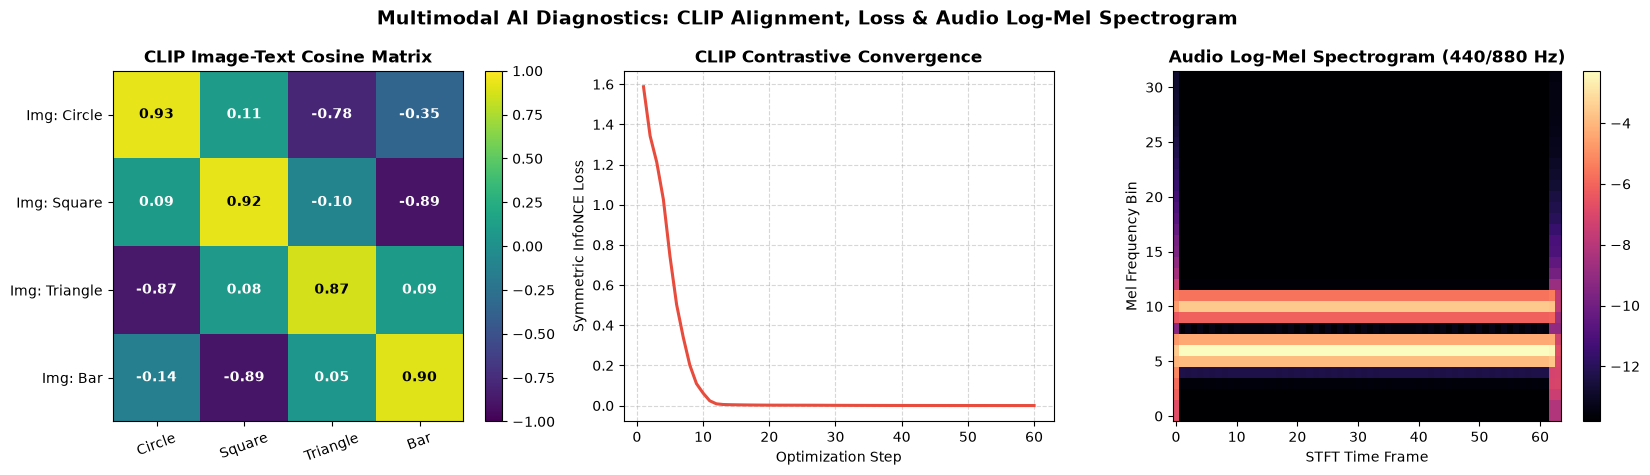

In [6]:
# Section 7: Diagnostics — Cross-Modal Similarity, CLIP Convergence & Log-Mel Spectrogram

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
fig.suptitle("Multimodal AI Diagnostics: CLIP Alignment, Loss & Audio Log-Mel Spectrogram", fontsize=14, fontweight="bold")

# Panel 1: CLIP Cosine Similarity Matrix
sim_np = sim_matrix.numpy()
im0 = axes[0].imshow(sim_np, cmap="viridis", vmin=-1.0, vmax=1.0)
axes[0].set_xticks(range(4))
axes[0].set_yticks(range(4))
axes[0].set_xticklabels(["Circle", "Square", "Triangle", "Bar"], rotation=20)
axes[0].set_yticklabels(["Img: Circle", "Img: Square", "Img: Triangle", "Img: Bar"])
axes[0].set_title("CLIP Image-Text Cosine Matrix", fontweight="bold")
for i in range(4):
    for j in range(4):
        axes[0].text(j, i, f"{sim_np[i, j]:.2f}", ha="center", va="center", color="white" if sim_np[i, j] < 0.4 else "black", fontweight="bold")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

# Panel 2: InfoNCE Convergence
axes[1].plot(range(1, len(clip_losses) + 1), clip_losses, color="#e74c3c", linewidth=2.2)
axes[1].set_xlabel("Optimization Step")
axes[1].set_ylabel("Symmetric InfoNCE Loss")
axes[1].set_title("CLIP Contrastive Convergence", fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Panel 3: Audio Log-Mel Spectrogram
im2 = axes[2].imshow(log_mel, aspect="auto", origin="lower", cmap="magma")
axes[2].set_xlabel("STFT Time Frame")
axes[2].set_ylabel("Mel Frequency Bin")
axes[2].set_title("Audio Log-Mel Spectrogram (440/880 Hz)", fontweight="bold")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Multimodal Interleaved Sequence Builder & Modality Mask
**Objective**:
Implement `assemble_interleaved_batch(text_emb, img_emb, insert_pos: int) -> Tuple[torch.Tensor, torch.Tensor]`:
1. Splices `img_emb` (`[B, N_img, D]`) into `text_emb` (`[B, N_txt, D]`) at index `insert_pos`.
2. Returns both the fused sequence and an integer `modality_ids` tensor (`0` for text, `1` for vision) so downstream MoE/modality-specific LayerNorms can route tokens cleanly.


In [7]:
# Exercise 1 Solution: Interleaved Multimodal Splicing & Modality Masking

def assemble_interleaved_batch(
    text_emb: torch.Tensor,
    img_emb: torch.Tensor,
    insert_pos: int
) -> Tuple[torch.Tensor, torch.Tensor]:
    B, N_txt, D = text_emb.shape
    N_img = img_emb.shape[1]
    
    fused = torch.cat([text_emb[:, :insert_pos, :], img_emb, text_emb[:, insert_pos:, :]], dim=1)
    mod_ids = torch.cat([
        torch.zeros((B, insert_pos), dtype=torch.long),
        torch.ones((B, N_img), dtype=torch.long),
        torch.zeros((B, N_txt - insert_pos), dtype=torch.long),
    ], dim=1)
    return fused, mod_ids

fused_out, mod_mask = assemble_interleaved_batch(torch.randn(2, 10, 64), torch.randn(2, 16, 64), insert_pos=4)
print(f"Fused Shape: {tuple(fused_out.shape)} | Modality Mask Vision Count: {(mod_mask[0] == 1).sum().item()}")

assert fused_out.shape == (2, 26, 64)
assert (mod_mask[:, 4:20] == 1).all() and (mod_mask[:, :4] == 0).all()
print(">>> EXERCISE 1 INTERLEAVED SEQUENCE BUILDER CERTIFIED! <<<")


Fused Shape: (2, 26, 64) | Modality Mask Vision Count: 16
>>> EXERCISE 1 INTERLEAVED SEQUENCE BUILDER CERTIFIED! <<<


#### Exercise 2: Dynamic Video Keyframe Deduplicator
**Objective**:
Sending 30 FPS video frames into a VLM wastes 90%+ of visual tokens when frames barely change.
Implement `extract_keyframes(frames: np.ndarray, mse_threshold: float = 0.02) -> List[int]` returning only frame indices whose normalized MSE change from the last retained keyframe exceeds `mse_threshold`.


In [8]:
# Exercise 2 Solution: Semantic Video Keyframe Deduplicator

def extract_keyframes(frames: np.ndarray, mse_threshold: float = 0.02) -> List[int]:
    if len(frames) == 0:
        return []
    retained = [0]
    last_kf = frames[0].astype(np.float32)
    for idx in range(1, len(frames)):
        mse = float(np.mean((frames[idx].astype(np.float32) - last_kf) ** 2))
        if mse >= mse_threshold:
            retained.append(idx)
            last_kf = frames[idx].astype(np.float32)
    return retained

# 10 synthetic frames: static scene frames 0-3, scene transition at 4, static 4-7, transition at 8
vid_frames = np.zeros((10, 16, 16), dtype=np.float32)
vid_frames[4:8] = 0.5
vid_frames[8:] = 1.0
vid_frames += rng.normal(0, 0.01, vid_frames.shape)

kfs = extract_keyframes(vid_frames, mse_threshold=0.05)
print(f"Compressed 10 raw frames -> {len(kfs)} keyframes at indices {kfs} ({100*(1 - len(kfs)/10):.0f}% token savings)")
assert kfs == [0, 4, 8], f"Expected keyframes [0, 4, 8], got {kfs}"
print(">>> EXERCISE 2 VIDEO KEYFRAME DEDUPLICATOR CERTIFIED! <<<")


Compressed 10 raw frames -> 3 keyframes at indices [0, 4, 8] (70% token savings)
>>> EXERCISE 2 VIDEO KEYFRAME DEDUPLICATOR CERTIFIED! <<<


### Challenge Problems

#### Challenge 1: Streaming Audio+Video Ring Buffer with PTS Synchronization
**Problem Formulation**:
Real-time multimodal assistants (like GPT-4o Live) ingest asynchronous audio chunks and video frames with Presentation Timestamps (`pts_ms`).
Implement `MultimodalSyncBuffer` that stores fixed-capacity audio and video streams and returns synchronized `(video_frame, audio_window)` pairs aligned within `tolerance_ms`.


In [9]:
# Challenge 1 Solution: PTS-Synchronized Audio+Video Streaming Buffer

class MultimodalSyncBuffer:
    def __init__(self, max_items: int = 32):
        self.video_q = deque(maxlen=max_items)
        self.audio_q = deque(maxlen=max_items)

    def push_video(self, pts_ms: float, frame_id: int) -> None:
        self.video_q.append((pts_ms, frame_id))

    def push_audio(self, pts_ms: float, chunk_id: int) -> None:
        self.audio_q.append((pts_ms, chunk_id))

    def fetch_aligned_pairs(self, tolerance_ms: float = 25.0) -> List[Dict[str, Any]]:
        pairs = []
        for v_pts, v_id in self.video_q:
            best_audio = min(self.audio_q, key=lambda a: abs(a[0] - v_pts), default=None)
            if best_audio and abs(best_audio[0] - v_pts) <= tolerance_ms:
                pairs.append({
                    "video_frame": v_id,
                    "audio_chunk": best_audio[1],
                    "pts_skew_ms": round(abs(best_audio[0] - v_pts), 2)
                })
        return pairs

sync_buf = MultimodalSyncBuffer()
for i in range(4):
    sync_buf.push_video(pts_ms=i * 100.0, frame_id=i)
    sync_buf.push_audio(pts_ms=i * 100.0 + 10.0, chunk_id=100 + i)

aligned = sync_buf.fetch_aligned_pairs(tolerance_ms=25.0)
print("Synchronized A/V Pairs:", aligned)
assert len(aligned) == 4 and all(p["pts_skew_ms"] == 10.0 for p in aligned)
print(">>> CHALLENGE 1 PTS-SYNCHRONIZED MULTIMODAL RING BUFFER CERTIFIED! <<<")


Synchronized A/V Pairs: [{'video_frame': 0, 'audio_chunk': 100, 'pts_skew_ms': 10.0}, {'video_frame': 1, 'audio_chunk': 101, 'pts_skew_ms': 10.0}, {'video_frame': 2, 'audio_chunk': 102, 'pts_skew_ms': 10.0}, {'video_frame': 3, 'audio_chunk': 103, 'pts_skew_ms': 10.0}]
>>> CHALLENGE 1 PTS-SYNCHRONIZED MULTIMODAL RING BUFFER CERTIFIED! <<<


#### Challenge 2: Zero-Shot Cross-Modal Retriever (`Text -> Image` Recall@1)
**Problem Formulation**:
Use our trained `MiniCLIP` dual encoder to build a zero-shot cross-modal search engine that indexes unseen noisy images and retrieves the matching target image given only a natural-language text query. Assert 100% Recall@1.


In [10]:
# Challenge 2 Solution: Zero-Shot CLIP Cross-Modal Retriever

# Generate unseen jittered evaluation images (jitter=2 pixels)
unseen_imgs = torch.stack([
    torch.from_numpy(np.asarray(render_shape_image(shape, color, size=32, jitter=2), dtype=np.float32) / 255.0).permute(2, 0, 1)
    for _, color, shape in CLASSES
])

with torch.no_grad():
    img_embs = F.normalize(clip_model.vision_encoder(unseen_imgs), dim=-1)
    txt_embs = F.normalize(clip_model.text_encoder(X_texts), dim=-1)
    t2i_scores = txt_embs @ img_embs.T
    top1_indices = t2i_scores.argmax(dim=-1).tolist()

print("Zero-Shot Text->Image Recall@1 Matches:", top1_indices)
assert top1_indices == [0, 1, 2, 3], f"Cross-modal retrieval mismatch: {top1_indices}"
print(">>> CHALLENGE 2 ZERO-SHOT CROSS-MODAL RETRIEVER CERTIFIED! <<<")


Zero-Shot Text->Image Recall@1 Matches: [0, 1, 2, 3]
>>> CHALLENGE 2 ZERO-SHOT CROSS-MODAL RETRIEVER CERTIFIED! <<<


### Further Reading & Production References
1. **Radford et al. (OpenAI, 2021)**: [Learning Transferable Visual Models From Natural Language Supervision (CLIP)](https://arxiv.org/abs/2103.00020).
2. **Liu et al. (2023)**: [Visual Instruction Tuning (LLaVA)](https://arxiv.org/abs/2304.08485) — Vision-to-LLM MLP projectors.
3. **Dosovitskiy et al. (ICLR 2021)**: [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale (ViT)](https://arxiv.org/abs/2010.11929).
4. **OpenAI (2024)**: [GPT-4o Native Omni Architecture System Card](https://openai.com/index/gpt-4o-system-card/).
5. **Alayrac et al. (DeepMind, 2022)**: [Flamingo: a Visual Language Model for Few-Shot Learning](https://arxiv.org/abs/2204.14198).
